In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [12]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [13]:
df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [14]:
df.shape

(2443651, 9)

In [15]:
df.dtypes

uid                    int64
asin                     str
title                    str
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category                 str
dtype: object

In [16]:
frequency_table = df['category'].value_counts()


proportion_table = df['category'].value_counts(normalize=True)

frequency_table.head(5), proportion_table

(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
 Name: count, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
                                             ...   
 Motorbike Chassis                         0.000044
 Alexa Built-In Devices                    0.000044
 Plugs                                     0.000044
 Smart Home Security & Lighting            0.000043
 Smart Speakers                            0.000022
 Name: proportion, Length: 296, dtype: float64)

En este conjunto de datos, Sports & Outdoors es la categoría con más productos anunciados, seguida de Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body y Birthday Gifts. Existe una gran diferencia entre la primera categoría y las demás.

C:\Users\salde\AppData\Local\Temp\ipykernel_37240\943092639.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frequency_table.head(5).index, y=frequency_table.head(5), palette="Set3");


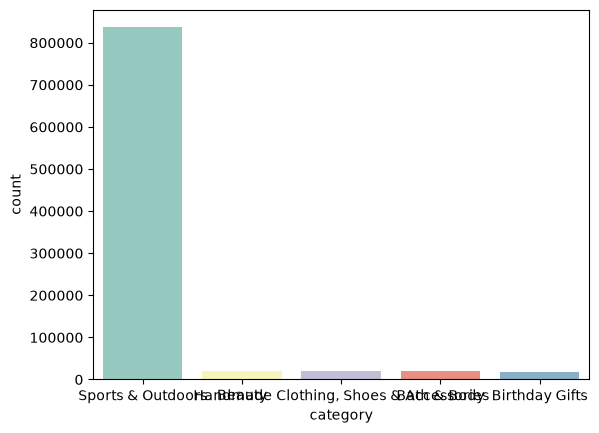

In [23]:
sns.barplot(x=frequency_table.head(5).index, y=frequency_table.head(5), palette="Set3");

C:\Users\salde\AppData\Local\Temp\ipykernel_37240\609578103.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frequency_table.head(5),y=frequency_table.head(5).index,palette="Set3");


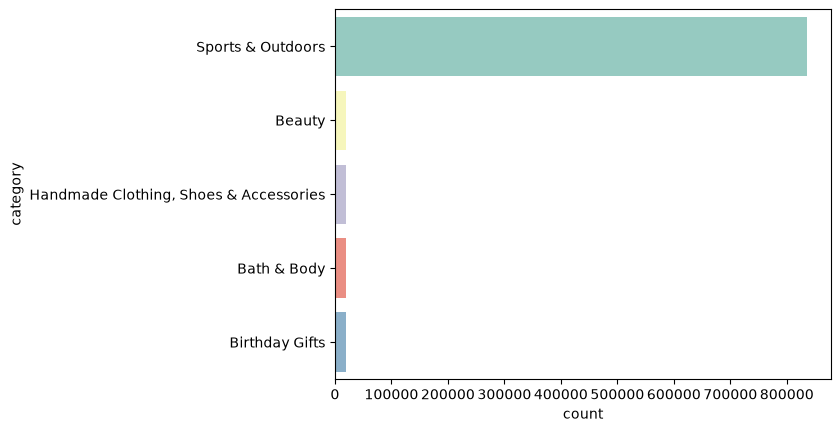

In [26]:
sns.barplot(x=frequency_table.head(5),y=frequency_table.head(5).index,palette="Set3");

<Axes: >

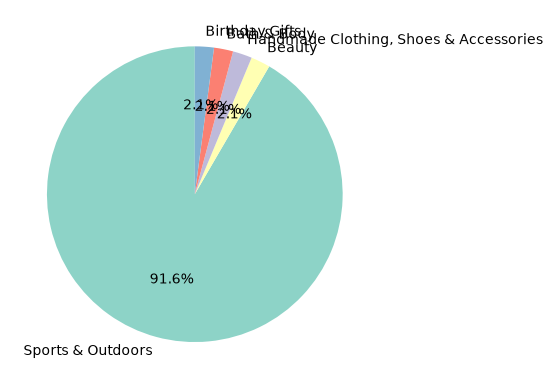

In [27]:
df['category'].value_counts().head(5).plot.pie(autopct='%.1f%%', startangle=90, colors=sns.color_palette("Set3"))

Sports & Outdoors domina entre las cinco categorías con más productos anunciados: representa el 91,6 % de los anuncios de este grupo.

In [28]:
mean_df = df['price'].mean()
median_df = df['price'].median()
mode_df = df['price'].mode()

mean_df, median_df, mode_df

(np.float64(89.24380943923661),
 np.float64(19.09),
 0    9.99
 Name: price, dtype: float64)

El precio medio es 89,24, mientras que el más frecuente es 9,99. La media también supera ampliamente la mediana de 19,09, lo que sugiere que los productos de precios elevados están aumentando el promedio. Lo comprobaremos con los gráficos.

In [31]:
std_df = df['price'].std()
var_df = df['price'].var()
range_df = df['price'].max() - df['price'].min()
quantiles_df = df['price'].quantile([0.25, 0.5, 0.75])
iqr_df = quantiles_df.loc[0.75] - quantiles_df.loc[0.25]

std_df, var_df, range_df,quantiles_df, iqr_df

(np.float64(345.60886175349873),
 np.float64(119445.48532254901),
 np.float64(100000.0),
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64,
 np.float64(36.0))

Aunque el 50 % central de los precios se sitúa entre 9,99 y 45,99, la desviación estándar y el rango son muy elevados. Esto indica una gran dispersión y sugiere la presencia de precios extremos, que revisaremos con los gráficos.

<Axes: xlabel='price', ylabel='Count'>

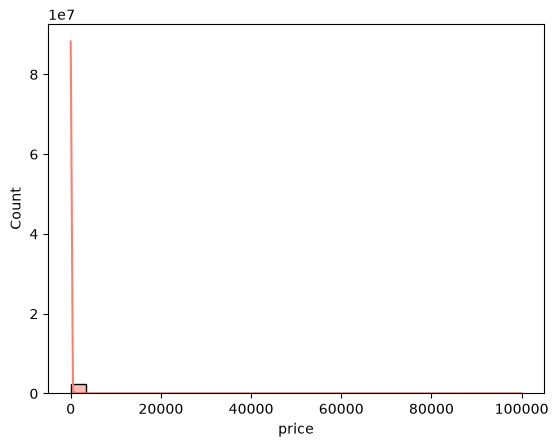

In [32]:
sns.histplot(df['price'], kde=True, bins=30, color="salmon")

Los precios extremos hacen que el histograma sea difícil de leer: el eje llega hasta 100.000 y los precios habituales quedan comprimidos a la izquierda.
Con 30 intervalos, cada barra abarca aproximadamente 3.333, demasiado para distinguir precios como 10, 20 o 50.
Podemos crear un segundo histograma mostrando solo los productos con precios hasta 200, conservando el original para ver el conjunto completo.

<Axes: xlabel='price', ylabel='Count'>

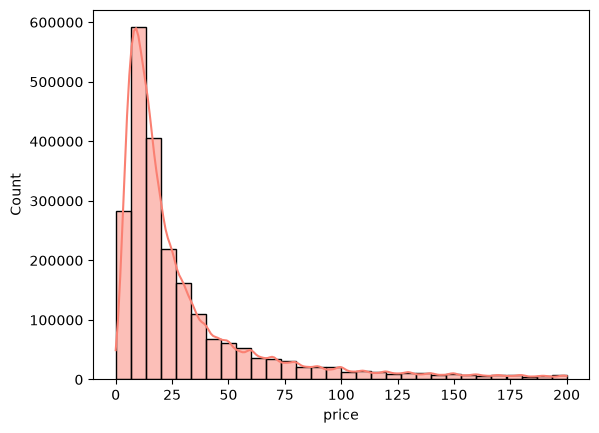

In [33]:
sns.histplot(df.loc[df['price'] <= 200, 'price'],kde=True,bins=30,color="salmon")

<Axes: ylabel='price'>

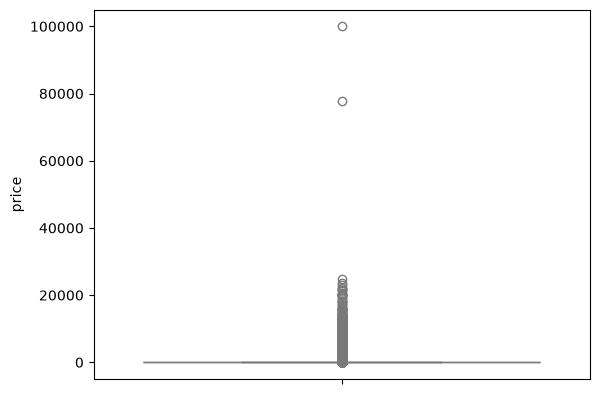

In [34]:
sns.boxplot(data = df['price'], color="lightblue")

Sí, hay productos con precios considerablemente superiores al resto. El boxplot muestra numerosos valores atípicos altos, mientras que el 50 % central de los precios está entre 9,99 y 45,99. Los valores extremos dificultan la visualización de la caja.

In [36]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()

mean_rating, median_rating, mode_rating

(np.float64(2.152836472966066),
 np.float64(0.0),
 0    0.0
 Name: stars, dtype: float64)

In [41]:
productos_valorados = df.loc[df['stars'] > 0]

In [42]:
print("Media:", df['stars'].mean())
print("Mediana:", df['stars'].median())
print("Moda:", df['stars'].mode())

Media: 2.152836472966066
Mediana: 0.0
Moda: 0    0.0
Name: stars, dtype: float64


In [43]:
print("Reseñas de los productos con 0 estrellas:")
print(df.loc[df['stars'] == 0, 'reviews'].value_counts())

Reseñas de los productos con 0 estrellas:
reviews
0    1225641
Name: count, dtype: int64


In [44]:
print("Estadísticas de productos con puntuación positiva:")
print("Media:", productos_valorados['stars'].mean())
print("Mediana:", productos_valorados['stars'].median())
print("Moda:", productos_valorados['stars'].mode())

Estadísticas de productos con puntuación positiva:
Media: 4.319160762226911
Mediana: 4.4
Moda: 0    4.5
Name: stars, dtype: float64


Al incluir todos los productos, la media es de 2,15 estrellas y la mediana y la moda son 0. Sin embargo, todos los productos con 0 estrellas tienen también 0 reseñas. Para analizar las valoraciones de los clientes, estudiamos por separado los productos con puntuación positiva: su media es de 4,32 estrellas, la mediana de 4,4 y la moda de 4,5. Estos resultados muestran una tendencia hacia valoraciones altas.

In [45]:
std_rating = df['stars'].std()
var_rating = df['stars'].var()
range_rating = df['stars'].max() - df['stars'].min()
quantiles_rating = df['stars'].quantile([0.25, 0.5, 0.75])
iqr_rating = quantiles_rating.loc[0.75] - quantiles_rating.loc[0.25]

std_rating, var_rating, range_rating, quantiles_rating, iqr_rating

(np.float64(2.194865378513421),
 np.float64(4.817434029796864),
 np.float64(5.0),
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64,
 np.float64(4.4))

In [46]:
std_valorados = productos_valorados['stars'].std()
var_valorados = productos_valorados['stars'].var()
quantiles_valorados = productos_valorados['stars'].quantile([0.25, 0.5, 0.75])
iqr_valorados = quantiles_valorados.loc[0.75] - quantiles_valorados.loc[0.25]

std_valorados, var_valorados, quantiles_valorados, iqr_valorados

(np.float64(0.5552867504620729),
 np.float64(0.3083433752387284),
 0.25    4.1
 0.50    4.4
 0.75    4.6
 Name: stars, dtype: float64,
 np.float64(0.5))

Entre los productos con valoración, las puntuaciones están bastante concentradas: el 50 % central se encuentra entre 4,1 y 4,6 estrellas. La desviación estándar de 0,56 indica una variación mucho menor que al incluir los ceros. La elevada dispersión inicial se debía en buena parte a mezclar productos sin valoraciones con productos valorados.

In [47]:
# Todos los productos
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

print("Todos los productos:")
print("Asimetría:", skewness_rating)
print("Curtosis:", kurtosis_rating)

# Productos con puntuación positiva
skewness_valorados = productos_valorados['stars'].skew()
kurtosis_valorados = productos_valorados['stars'].kurtosis()

print("\nProductos con puntuación positiva:")
print("Asimetría:", skewness_valorados)
print("Curtosis:", kurtosis_valorados)

Todos los productos:
Asimetría: 0.08120735761080881
Curtosis: -1.9260061280432994

Productos con puntuación positiva:
Asimetría: -2.379568112212799
Curtosis: 9.78193769066435


Entre los productos valorados, predominan las puntuaciones altas, pero existen puntuaciones bajas que alargan la cola hacia la izquierda. La asimetría negativa y la curtosis elevada indican que la distribución no tiene una forma normal. Al incluir los productos sin valoraciones, la asimetría queda cerca de cero, pero esto no significa que los datos sigan una distribución normal.

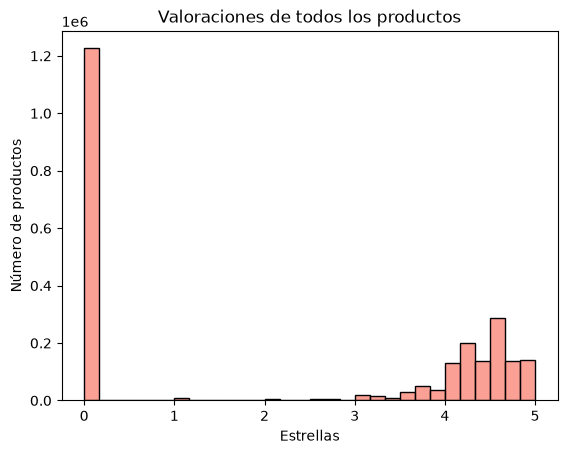

In [48]:
sns.histplot(df['stars'], bins=30, color="salmon")
plt.title("Valoraciones de todos los productos")
plt.xlabel("Estrellas")
plt.ylabel("Número de productos")
plt.show()

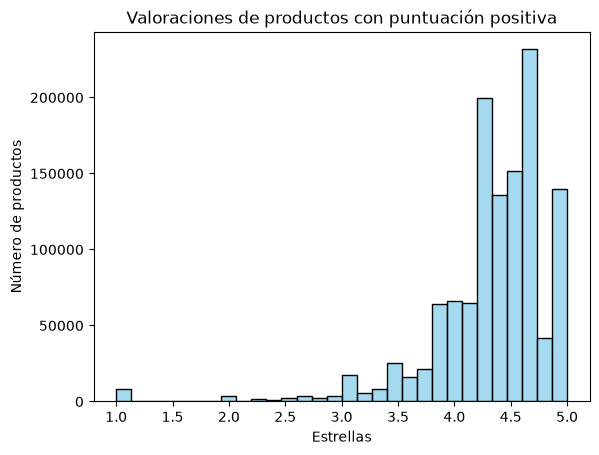

In [49]:
sns.histplot(productos_valorados['stars'], bins=30, color="skyblue")
plt.title("Valoraciones de productos con puntuación positiva")
plt.xlabel("Estrellas")
plt.ylabel("Número de productos")
plt.show()

En el primer histograma destaca una gran concentración en 0 estrellas, correspondiente a productos sin reseñas. Al analizar únicamente los productos con puntuación positiva, las valoraciones se concentran principalmente entre 4 y 5 estrellas. La puntuación más frecuente es 4,5, según la moda calculada anteriormente.
El segundo histograma muestra una cola hacia las puntuaciones bajas, coherente con la asimetría negativa. Por tanto, predominan las valoraciones altas entre los productos valorados, aunque existen algunos con puntuaciones bajas.

## Conclusiones finales

### 1. Categorías de productos

Sports & Outdoors es la categoría con más productos anunciados: cuenta con **836.265** y representa el **91,6 % de los anuncios entre las cinco categorías principales**.

Esto muestra una elevada concentración de la oferta en esta categoría dentro del dataset, pero no permite afirmar que sea la que más vende.

### 2. Precios

El precio medio es **89,24**, bastante superior a la mediana de **19,09** y a la moda de **9,99**. Los precios elevados aumentan la media, mientras que el 50 % central de los precios se encuentra entre **9,99 y 45,99**.

Para orientar una decisión de precios, convendría comparar productos de la misma categoría y utilizar la mediana como referencia inicial, ya que el promedio general está muy influido por los valores extremos.

### 3. Valoraciones

Los **1.225.641 productos con 0 estrellas también tienen 0 reseñas**, por lo que interpretamos estos ceros como ausencia de valoraciones.

Entre los productos con puntuación positiva:

- La media es de **4,32 estrellas**.
- La puntuación más frecuente es **4,5 estrellas**.
- El 50 % central de las puntuaciones se encuentra entre **4,1 y 4,6 estrellas**.

Predominan las valoraciones altas. Para comparar productos, convendría considerar tanto su puntuación como el número de reseñas que la respalda.

### Conclusión de negocio y próximos pasos

El análisis permite conocer cómo se distribuyen la oferta, los precios y las valoraciones en el dataset. Sin embargo, **estos resultados por sí solos no permiten determinar qué productos tienen más demanda ni tomar decisiones de inventario**.

Los siguientes pasos serían:

- Comparar precios y valoraciones dentro de cada categoría.
- Revisar los productos con precios extremos.
- Incorporar información sobre ventas, costes y márgenes para evaluar oportunidades de negocio.